# UCSF-PDGM clean study: clinical only, MRI only, multimodal, and missing clinical data
Run the cells from top to bottom (Runtime > Run all also works). Order of work:
1. **BINARY** (grade 2/3 vs grade 4): clinical only, MRI only, MRI + clinical, MRI + clinical with missing clinical data.
2. **3-CLASS** (grade 2 / 3 / 4): the same four parts.
3. A final report and result files are written at the end.

To use other models, edit the **SETTINGS** cell only (see the comments there).

# **0. SETUP**

In [37]:
# Install the libraries (Colab already has most of them)
!pip -q install datasets scikit-learn pandas matplotlib openpyxl torch torchvision

In [38]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

# **1. LOAD DATA**
One row = one patient (one tumour slice, 4 MRI sequences, age, sex, grade).

In [39]:
# 1) Dataset load aur inspect
from datasets import load_dataset, Image as HFImage

ds = load_dataset("MedOtter/UCSF-PDGM")
print(ds)
split = list(ds.keys())[0]
d = ds[split]
print("split:", split, "| rows:", len(d))
img_cols = [k for k, v in d.features.items() if isinstance(v, HFImage)]
print("image columns:", img_cols)
print("other columns:", [k for k in d.features if k not in img_cols])

DatasetDict({
    test: Dataset({
        features: ['patient_id', 'sex', 'age_at_mri', 'who_cns_grade', 'diagnosis_who2021', 'idh', 'mgmt_status', 'brats21_id', 'os_days', 'dead', 'num_slices', 'tumor_slice_idx', 'tumor_voxels', 'T1', 'T1c', 'T2', 'FLAIR', 'tumor_mask', 'overlay_T1c'],
        num_rows: 495
    })
})
split: test | rows: 495
image columns: ['T1', 'T1c', 'T2', 'FLAIR', 'tumor_mask', 'overlay_T1c']
other columns: ['patient_id', 'sex', 'age_at_mri', 'who_cns_grade', 'diagnosis_who2021', 'idh', 'mgmt_status', 'brats21_id', 'os_days', 'dead', 'num_slices', 'tumor_slice_idx', 'tumor_voxels']


In [40]:
# 2) Metadata (images ke baghair) aur sahi columns dhoondo
import re, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

meta = d.remove_columns(img_cols).to_pandas()
print(meta.shape)
print(meta.head(3).T)

ID_COL = next(c for c in meta.columns
              if meta[c].astype(str).str.match(r"^UCSF-PDGM-\d+").mean() > 0.9)
GRADE_COL = next(c for c in meta.columns if "grade" in c.lower() and "brats" not in c.lower())
AGE_COL = next(c for c in meta.columns if c.lower().startswith("age"))
SEX_COL = next(c for c in meta.columns if c.lower().startswith("sex"))
print("Using:", dict(id=ID_COL, grade=GRADE_COL, age=AGE_COL, sex=SEX_COL))

(495, 13)
                                            0                           1  \
patient_id                     UCSF-PDGM-0004              UCSF-PDGM-0005   
sex                                         M                           F   
age_at_mri                                 66                          80   
who_cns_grade                               4                           4   
diagnosis_who2021  Glioblastoma, IDH-wildtype  Glioblastoma, IDH-wildtype   
idh                                  wildtype                    wildtype   
mgmt_status                          negative               indeterminate   
brats21_id                    BraTS2021_00097                               
os_days                                  1303                         274   
dead                                        1                           1   
num_slices                                155                         155   
tumor_slice_idx                           105                     

In [41]:
# 3) Patient table (ek row = ek patient) aur label
patients = pd.DataFrame({
    "row": np.arange(len(d)),
    "patient_id": meta[ID_COL].astype(str),
    "sex": meta[SEX_COL].astype(str).str.strip().str.upper().str[0],
    "age": pd.to_numeric(meta[AGE_COL].astype(str).str.extract(r"(\d+\.?\d*)")[0], errors="coerce"),
    "who_grade": pd.to_numeric(meta[GRADE_COL].astype(str).str.extract(r"(\d)")[0], errors="coerce"),
})
patients["sex_m"] = patients["sex"].map({"M": 1.0, "F": 0.0})        # M=1, F=0, baaki NaN

print("duplicate patient ids:", patients["patient_id"].duplicated().sum())
patients = patients.drop_duplicates("patient_id").reset_index(drop=True)
print("grade counts:", patients["who_grade"].value_counts(dropna=False).to_dict())
print("sex counts:", patients["sex"].value_counts(dropna=False).to_dict())
print("age missing:", patients["age"].isna().sum(), "| age range:", patients["age"].min(), "-", patients["age"].max())

patients = patients.dropna(subset=["who_grade"]).reset_index(drop=True)
patients["y"] = (patients["who_grade"] == 4).astype(int)            # grade 4 -> 1, grade 2/3 -> 0
print("used patients:", len(patients), "| grade 4:", int(patients["y"].sum()),
      "| grade 2/3:", int((patients["y"] == 0).sum()),
      "| always-grade-4 accuracy:", round(patients["y"].mean(), 3))

# Leakage guard: sirf age aur sex features hain
CLINICAL_FEATURES = ["age", "sex_m"]

duplicate patient ids: 0
grade counts: {4: 396, 2: 56, 3: 43}
sex counts: {'M': 296, 'F': 199}
age missing: 0 | age range: 17 - 94
used patients: 495 | grade 4: 396 | grade 2/3: 99 | always-grade-4 accuracy: 0.8


# **2. MRI NUMBERS** (frozen ResNet50, no training)
The numbers are saved in `embeddings.npz`, so this step runs only once.

In [42]:
# 6a) Frozen ResNet50 (ImageNet) se features. Koi training nahi, sirf forward pass.
import torch, torchvision
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

device = "cuda" if torch.cuda.is_available() else "cpu"
_model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
_model.fc = torch.nn.Identity()
_model = _model.eval().to(device)
_tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor(),
                          transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

@torch.no_grad()
def extract_embeddings(pil_images, batch_size=32):
    out = []
    for i in range(0, len(pil_images), batch_size):
        x = torch.stack([_tf(im.convert("RGB")) for im in pil_images[i:i + batch_size]]).to(device)
        out.append(_model(x).cpu().numpy())
    return np.concatenate(out)

In [43]:
# 6b) Har sequence ke liye embeddings nikaalo aur save karo (dobara nahi chalana padega)
import os
SEQS = [c for c in img_cols if c.lower() in ("t1", "t1c", "t2", "flair")]
print("sequences used:", SEQS)

if os.path.exists("embeddings.npz"):
    emb = dict(np.load("embeddings.npz"))
    print("loaded saved embeddings")
else:
    emb = {}
    rows = patients["row"].astype(int).tolist()
    for s in SEQS:
        dseq = d.select_columns([s])
        imgs = [dseq[i][s] for i in rows]
        emb[s] = extract_embeddings(imgs)
        print(s, emb[s].shape)
    np.savez("embeddings.npz", **emb)
assert all(emb[s].shape[0] == len(patients) for s in SEQS)

sequences used: ['T1', 'T1c', 'T2', 'FLAIR']
loaded saved embeddings


# **3. SETTINGS AND MODEL CHOICES**

In [44]:
# ================= SETTINGS: change things only here =================
SEEDS   = [42, 43, 44]      # the whole study is repeated 3 times with different patient splits
N_FOLDS = 5                 # patient-level 5-fold cross-validation
N_PCA   = 32                # the MRI numbers of each patient are reduced to 32 numbers
MRI_SEQUENCES = ["T1", "T1c", "T2", "FLAIR"]   # use ["T1c"] to try one sequence only
TRAIN_WITH_MISSING = True  # False: train on complete clinical data. True: also train with random missing values
TAG = "train_with_missing" if TRAIN_WITH_MISSING else "train_complete"   # added to every output file name, so runs never overwrite each other

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

# ---- Model recipes. Each function returns a NEW untrained model. The function name is used as the model name in all tables ----
def logistic_regression(): return LogisticRegression(C=0.1, class_weight="balanced", max_iter=3000)
def decision_tree():       return DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, class_weight="balanced", random_state=0)
def random_forest():       return RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced", random_state=0, n_jobs=-1)
# Two more ready recipes (NOT used until you add their names to the lists below):
def svm():                       return SVC(C=1.0, kernel="rbf", probability=True, class_weight="balanced", random_state=0)
def hist_gradient_boosting():    return HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, class_weight="balanced", random_state=0)
# Example: MULTIMODAL_MODELS = [logistic_regression, decision_tree, random_forest, svm, hist_gradient_boosting]
# You can write your own the same way. Every recipe must be its own "def" so that it has a name.

# ---- Which models are used in each part. To replace a model, change its name in the list (the tables relabel themselves) ----
#MRI_MODELS        = [logistic_regression, decision_tree, random_forest]
#CLINICAL_MODELS   = [logistic_regression, decision_tree, random_forest]
#MULTIMODAL_MODELS = [logistic_regression, decision_tree, random_forest]
MRI_MODELS        = [logistic_regression, decision_tree, random_forest, svm, hist_gradient_boosting]
CLINICAL_MODELS   = [logistic_regression, decision_tree, random_forest, svm, hist_gradient_boosting]
MULTIMODAL_MODELS = [logistic_regression, decision_tree, random_forest, svm, hist_gradient_boosting]

def model_name(make_model):
    name = make_model.__name__.replace("_", " ").title()
    return {"Svm": "SVM", "Knn": "KNN", "Xgboost": "XGBoost"}.get(name, name)

# ---- How much clinical data is hidden in the missing-data part (test patients only) ----
MISSING_SCENARIOS = ["0% missing", "25% missing", "50% missing", "75% missing", "100% missing",
                     "only age missing", "only sex missing"]

# ---- Main metric of each task (used to pick the "best" model) ----
PRIMARY = {"binary": "mcc", "3class": "macro_f1"}

# **4. HELPER FUNCTIONS AND THE FOUR PARTS**

In [45]:
# ================= HELPER FUNCTIONS (you do not need to change these) =================
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score, recall_score)

age_all = patients["age"].values.astype(float)
sex_all = patients["sex_m"].values.astype(float)               # M = 1, F = 0
X_mri_all = np.concatenate([emb[s] for s in MRI_SEQUENCES], axis=1)   # each MRI sequence gives 2048 numbers per patient

def get_folds(y):
    """Yield (seed, fold, train_idx, test_idx). One row = one patient, so every split is patient-level."""
    for seed in SEEDS:
        for k, (tr, te) in enumerate(StratifiedKFold(N_FOLDS, shuffle=True, random_state=seed).split(X_mri_all, y)):
            yield seed, k, tr, te

def mri_features(tr, te):
    """MRI numbers -> 32 numbers per patient. Learned on the training patients only."""
    scaler = StandardScaler().fit(X_mri_all[tr])
    pca = PCA(n_components=min(N_PCA, len(tr) - 1), whiten=True, random_state=0).fit(scaler.transform(X_mri_all[tr]))
    to_features = lambda idx: pca.transform(scaler.transform(X_mri_all[idx]))
    return to_features(tr), to_features(te)

def clinical_stats(tr):
    """Average age and most common sex of the training patients (used to fill missing values)."""
    return dict(age_mean=np.nanmean(age_all[tr]), age_sd=np.nanstd(age_all[tr]) or 1.0,
                sex_mode=float(pd.Series(sex_all[tr]).mode().iloc[0]))

def clinical_features(age, sex, stats):
    """Clinical table with 4 columns: age (scaled), sex, age_is_missing, sex_is_missing."""
    age_missing, sex_missing = np.isnan(age), np.isnan(sex)
    age_filled = np.where(age_missing, stats["age_mean"], age)
    sex_filled = np.where(sex_missing, stats["sex_mode"], sex)
    return np.column_stack([(age_filled - stats["age_mean"]) / stats["age_sd"], sex_filled,
                            age_missing.astype(float), sex_missing.astype(float)])

def hide_clinical(age, sex, scenario, rng):
    """Remove clinical values to simulate missing data."""
    age, sex = age.copy(), sex.copy()
    if scenario == "only age missing":
        age[:] = np.nan
    elif scenario == "only sex missing":
        sex[:] = np.nan
    else:                                   # for example "50% missing": that share of patients loses BOTH age and sex
        share = int(scenario.split("%")[0]) / 100
        chosen = rng.choice(len(age), int(round(share * len(age))), replace=False)
        age[chosen] = np.nan
        sex[chosen] = np.nan
    return age, sex

def hide_randomly(age, sex, rng, p=0.4):
    """Used only when TRAIN_WITH_MISSING = True: hide each value with probability p."""
    age, sex = age.copy(), sex.copy()
    age[rng.random(len(age)) < p] = np.nan
    sex[rng.random(len(sex)) < p] = np.nan
    return age, sex

def score(model_name, seed, k, y_true, proba, class_names, **extra):
    """All metrics of one model on one test fold."""
    n = len(class_names)
    assert proba.shape[1] == n, "model output does not match the number of classes"
    pred = proba.argmax(axis=1)
    try:
        auc = roc_auc_score(y_true, proba[:, 1]) if n == 2 else \
              roc_auc_score(y_true, proba, multi_class="ovr", average="macro", labels=list(range(n)))
    except ValueError:
        auc = np.nan
    row = dict(model=model_name, seed=seed, fold=k, mcc=matthews_corrcoef(y_true, pred),
               balanced_acc=balanced_accuracy_score(y_true, pred), macro_f1=f1_score(y_true, pred, average="macro"),
               auc=auc, accuracy=accuracy_score(y_true, pred))
    for name, r in zip(class_names, recall_score(y_true, pred, average=None, labels=list(range(n)))):
        row["recall " + name] = r
    row.update(extra)
    return row

In [46]:
# ================= THE FOUR PARTS OF THE STUDY =================

def run_clinical_only(y, class_names):
    """PART 1: only clinical data (age, sex)."""
    rows = []
    for seed, k, tr, te in get_folds(y):
        stats = clinical_stats(tr)
        C_tr = clinical_features(age_all[tr], sex_all[tr], stats)
        C_te = clinical_features(age_all[te], sex_all[te], stats)
        for make_model in CLINICAL_MODELS:
            name = model_name(make_model)
            model = make_model().fit(C_tr, y[tr])
            rows.append(score(name, seed, k, y[te], model.predict_proba(C_te), class_names))
    return pd.DataFrame(rows)

def run_mri_only(y, class_names):
    """PART 2: only MRI (4 sequences)."""
    rows = []
    for seed, k, tr, te in get_folds(y):
        Z_tr, Z_te = mri_features(tr, te)
        for make_model in MRI_MODELS:
            name = model_name(make_model)
            model = make_model().fit(Z_tr, y[tr])
            rows.append(score(name, seed, k, y[te], model.predict_proba(Z_te), class_names))
    return pd.DataFrame(rows)

def run_multimodal(y, class_names):
    """PART 3: MRI + clinical data together (the two sets of numbers are placed side by side)."""
    rows = []
    for seed, k, tr, te in get_folds(y):
        Z_tr, Z_te = mri_features(tr, te)
        stats = clinical_stats(tr)
        X_tr = np.hstack([Z_tr, clinical_features(age_all[tr], sex_all[tr], stats)])
        X_te = np.hstack([Z_te, clinical_features(age_all[te], sex_all[te], stats)])
        for make_model in MULTIMODAL_MODELS:
            name = model_name(make_model)
            model = make_model().fit(X_tr, y[tr])
            rows.append(score(name, seed, k, y[te], model.predict_proba(X_te), class_names))
    return pd.DataFrame(rows)

def run_missing_clinical(y, class_names):
    """PART 4: the same trained models are tested while clinical data is hidden (MRI-only is included as a reference)."""
    rows = []
    for seed, k, tr, te in get_folds(y):
        Z_tr, Z_te = mri_features(tr, te)
        stats = clinical_stats(tr)
        age_fit, sex_fit, Z_fit, y_fit = age_all[tr], sex_all[tr], Z_tr, y[tr]
        if TRAIN_WITH_MISSING:               # add a second copy of the training patients with random missing values
            age2, sex2 = hide_randomly(age_all[tr], sex_all[tr], np.random.default_rng(seed * 100 + k))
            age_fit, sex_fit = np.concatenate([age_fit, age2]), np.concatenate([sex_fit, sex2])
            Z_fit, y_fit = np.vstack([Z_fit, Z_tr]), np.concatenate([y_fit, y[tr]])
        C_fit = clinical_features(age_fit, sex_fit, stats)

        trained = {}                          # train every model once
        for make_model in MRI_MODELS:
            trained["MRI - " + model_name(make_model)] = ("mri", make_model().fit(Z_fit, y_fit))
        for make_model in CLINICAL_MODELS:
            trained["Clinical - " + model_name(make_model)] = ("clinical", make_model().fit(C_fit, y_fit))
        for make_model in MULTIMODAL_MODELS:
            trained["MRI+Clinical - " + model_name(make_model)] = ("both", make_model().fit(np.hstack([Z_fit, C_fit]), y_fit))

        for i, scenario in enumerate(MISSING_SCENARIOS):
            rng = np.random.default_rng(seed * 1000 + k * 10 + i)      # same hidden patients for every model
            age_te, sex_te = hide_clinical(age_all[te], sex_all[te], scenario, rng)
            C_te = clinical_features(age_te, sex_te, stats)
            for name, (kind, model) in trained.items():
                if kind == "mri":        X_te = Z_te
                elif kind == "clinical": X_te = C_te
                else:                    X_te = np.hstack([Z_te, C_te])
                rows.append(score(name, seed, k, y[te], model.predict_proba(X_te), class_names, scenario=scenario))
    out = pd.DataFrame(rows)
    out["scenario"] = pd.Categorical(out["scenario"], MISSING_SCENARIOS, ordered=True)
    return out

In [47]:
# ================= TABLES, FIGURE, FILES, REPORT =================

def summarize(df, by):
    """Mean and standard deviation over all seeds and folds."""
    cols = [c for c in df.columns if c not in ("model", "scenario", "seed", "fold")]
    grouped = df.groupby(by, observed=True)[cols]
    return grouped.mean(), grouped.std()

def show_columns(df):
    main = [c for c in ["mcc", "balanced_acc", "macro_f1", "auc", "accuracy"] if c in df.columns]
    return main + [c for c in df.columns if c.startswith("recall ")]

def pretty(mean, sd, cols):
    out = pd.DataFrame(index=mean.index)
    for c in cols:
        out[c] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(mean[c], sd[c])]
    return out

def show(title, df):
    """Print one results table (one row per model)."""
    mean, sd = summarize(df, ["model"])
    display(Markdown(f"### **{title}**"))
    display(pretty(mean, sd, show_columns(df)))

def show_missing(title, df, task):
    """Print the missing-data results: rows = models, columns = how much clinical data is missing."""
    mean, sd = summarize(df, ["model", "scenario"])
    display(Markdown(f"### **{title}**"))
    for metric in [PRIMARY[task], "balanced_acc"]:
        display(Markdown(f"**{metric}** (mean ± sd over seeds and folds)"))
        display(pretty(mean, sd, [metric])[metric].unstack("scenario"))

def plot_missing(df, task, filename):
    """Line plot: main metric against the percentage of patients with missing clinical data (best model of each kind)."""
    primary = PRIMARY[task]
    levels = [s for s in MISSING_SCENARIOS if s.endswith("% missing")]
    mean = df[df["scenario"].isin(levels)].groupby(["model", "scenario"], observed=True)[primary].mean().unstack()[levels]
    plt.figure(figsize=(7, 4.5))
    for kind in ["MRI - ", "Clinical - ", "MRI+Clinical - "]:
        part = mean[mean.index.str.startswith(kind)]
        best = part["0% missing"].idxmax()
        plt.plot([int(s.split("%")[0]) for s in levels], part.loc[best].values, marker="o", label=best)
    plt.xlabel("Patients with clinical data removed (%)"); plt.ylabel(primary)
    plt.title(f"Effect of missing clinical data ({task})"); plt.legend(fontsize=8); plt.grid(alpha=.3)
    plt.tight_layout(); plt.savefig(filename, dpi=200); plt.show()

PART_SHEETS = [("1 Clinical only", "clinical", ["model"]), ("2 MRI only", "mri", ["model"]),
               ("3 MRI+Clinical", "multimodal", ["model"]), ("4 Missing clinical", "missing", ["model", "scenario"])]

def save_task(task, res):
    """One Excel file per task: one sheet per part (each model has its own row) + raw results of every fold."""
    with pd.ExcelWriter(f"results_{task}_{TAG}.xlsx") as xl:
        for sheet, key, by in PART_SHEETS:
            mean, sd = summarize(res[key], by)
            pretty(mean, sd, show_columns(res[key])).to_excel(xl, sheet_name=sheet)
        pd.concat([d.assign(part=k) for k, d in res.items()]).to_excel(xl, sheet_name="raw folds", index=False)

def md_table(df):
    header = "| model | " + " | ".join(df.columns) + " |"
    lines = [header, "|" + "---|" * (len(df.columns) + 1)]
    lines += ["| " + str(i) + " | " + " | ".join(r) + " |" for i, r in zip(df.index, df.values.tolist())]
    return "\n".join(lines)

def task_report(task, title, y, class_names, res):
    primary = PRIMARY[task]
    pname = {"mcc": "MCC", "macro_f1": "macro-F1"}[primary]
    counts = ", ".join(f"{n}: {int((y == i).sum())}" for i, n in enumerate(class_names))
    L = [f"## {title}", "", f"Patients: {len(y)} ({counts}). Main metric: {pname}. "
         f"Every number is mean ± standard deviation over {len(SEEDS)} seeds x {N_FOLDS} patient-level folds.", ""]
    best_mri = None
    for heading, key in [("Part 1. Clinical only (age, sex)", "clinical"), ("Part 2. MRI only", "mri"),
                         ("Part 3. MRI + clinical (multimodal)", "multimodal")]:
        mean, sd = summarize(res[key], ["model"])
        best = mean[primary].idxmax()
        if key == "mri": best_mri = (best, mean.loc[best, primary])
        L += [f"### {heading}", f"Models used: {', '.join(mean.index)}.",
              f"Best by {pname}: **{best}** ({mean.loc[best, primary]:.3f}).", "",
              md_table(pretty(mean, sd, show_columns(res[key]))), ""]
    mean, sd = summarize(res["missing"], ["model", "scenario"])
    table = pretty(mean, sd, [primary])[primary].unstack("scenario")[MISSING_SCENARIOS]
    L += ["### Part 4. MRI + clinical with missing clinical data", f"Table: {pname} for each model and each amount of missing clinical data.", "",
          md_table(table), "", "Effect of missing clinical data on each multimodal model:", ""]
    for name in [m for m in mean.index.get_level_values("model").unique() if m.startswith("MRI+Clinical")]:
        full, none = mean.loc[(name, "0% missing"), primary], mean.loc[(name, "100% missing"), primary]
        spread = sd.loc[(name, "0% missing"), primary]
        note = "inside the fold-to-fold spread" if abs(none - full) <= spread else "larger than the fold-to-fold spread"
        L.append(f"- {name}: {pname} {full:.3f} with full clinical data and {none:.3f} with all clinical data missing "
                 f"(change {none - full:+.3f}, {note}). Only age missing: {mean.loc[(name, 'only age missing'), primary]:.3f}; "
                 f"only sex missing: {mean.loc[(name, 'only sex missing'), primary]:.3f}.")
    clin = [m for m in mean.index.get_level_values("model").unique() if m.startswith("Clinical")]
    L += ["", "Reference points with all clinical data missing: "
          + "; ".join(f"{m} {mean.loc[(m, '100% missing'), primary]:.3f}" for m in clin)
          + f"; best MRI-only model ({best_mri[0]}) {best_mri[1]:.3f}.", ""]
    return "\n".join(L)

PREVIOUS_WORK = """## Previous work and earlier runs

- Kheirbakhsh et al. (2026, medRxiv preprint, not peer reviewed): UCSF-PDGM, 495 patients, MRI + age + sex, grade 2&3 vs 4, slice-level evaluation with fine-tuned DenseNet121. Clinical-only: accuracy 0.80, MCC 0.44. Best single MRI sequence (T1c): accuracy 0.83, MCC 0.48. Best fusion: accuracy 0.86, MCC 0.54. Check the numbers in the PDF before citing. A missing-clinical-data test was not seen in that paper.
- Earlier run in this project (notebook 04, binary task, frozen ResNet50 features, mean over 3 seeds x 5 folds): MRI-only MCC 0.392; clinical-only MCC 0.451; concatenation fusion MCC 0.447; with all clinical data removed fusion MCC 0.361, MRI-only 0.392, clinical-only 0.000.
- Earlier scratch-CNN baseline (tumor.ipynb, 3 classes, MRI only, one split of 75 test patients): accuracy 0.8133, balanced accuracy 0.4019, macro-F1 0.3978; almost every patient was predicted as grade 4.

These earlier numbers use other models and settings, so compare only the direction of the effects."""

LIMITS = """## How to read these results

- No significance tests are included here. Differences smaller than the standard deviation should not be treated as real.
- One tumour slice per patient, MRI described by frozen ResNet50 features (no fine-tuning), only age and sex as clinical data.
- Missing clinical data is simulated by hiding values; it is not real hospital missingness.
- Grade 2 and grade 3 have few patients, so three-class results (especially their per-class recall) are unstable.
- Dataset: UCSF-PDGM (Calabrese et al., 2022), Hugging Face copy MedOtter/UCSF-PDGM (CC BY 4.0). Cite the original dataset."""

def make_report(runs):
    """Write final_report.md: models used, results of every part, effect of missing clinical data, earlier work."""
    names = lambda models: ", ".join(model_name(m) for m in models)
    models = (f"MRI models: {names(MRI_MODELS)}. Clinical models: {names(CLINICAL_MODELS)}. "
              f"Multimodal models: {names(MULTIMODAL_MODELS)}. Training with missing values: {TRAIN_WITH_MISSING}.")
    parts = ["# Final report: MRI, clinical and multimodal glioma grade classification (UCSF-PDGM)", "",
             "## What was done", "",
             f"- Data: {len(patients)} patients, one tumour slice per patient, 4 MRI sequences (T1, T1c, T2, FLAIR) and age + sex.",
             "- MRI features: frozen ResNet50 (ImageNet) numbers, reduced with PCA.",
             f"- {models}",
             f"- Evaluation: {N_FOLDS}-fold patient-level cross-validation repeated with seeds {SEEDS}.",
             "- Order of work: binary task first (grade 4 vs grade 2/3), then three classes (grade 2 / 3 / 4). "
             "Each task has four parts: clinical only, MRI only, MRI + clinical, MRI + clinical with missing clinical data.", ""]
    for task, title, y, names, res in runs:
        parts.append(task_report(task, title, y, names, res))
    parts += [PREVIOUS_WORK, "", LIMITS, ""]
    text = "\n".join(parts)
    with open(f"final_report_{TAG}.md", "w", encoding="utf-8") as f:
        f.write(text)
    return text

# **BINARY CLASSIFICATION: grade 2/3 vs grade 4**

## **PART 1: CLINICAL ONLY**

In [48]:
y_bin = (patients["who_grade"] == 4).astype(int).values      # grade 4 = 1, grade 2 or 3 = 0
names_bin = ["grade 2/3", "grade 4"]
binary = {}

binary["clinical"] = run_clinical_only(y_bin, names_bin)
show("BINARY | PART 1: CLINICAL ONLY (age, sex)", binary["clinical"])

### **BINARY | PART 1: CLINICAL ONLY (age, sex)**

,mcc,balanced_acc,macro_f1,auc,accuracy,recall grade 2/3,recall grade 4
model,,,,,,,
Decision Tree,0.435 ± 0.062,0.744 ± 0.035,0.708 ± 0.032,0.757 ± 0.053,0.785 ± 0.027,0.677 ± 0.076,0.812 ± 0.036
Hist Gradient Boosting,0.439 ± 0.061,0.749 ± 0.033,0.709 ± 0.033,0.755 ± 0.054,0.783 ± 0.029,0.693 ± 0.058,0.806 ± 0.034
Logistic Regression,0.425 ± 0.059,0.749 ± 0.037,0.693 ± 0.028,0.795 ± 0.052,0.761 ± 0.023,0.730 ± 0.081,0.769 ± 0.032
Random Forest,0.389 ± 0.083,0.715 ± 0.043,0.687 ± 0.045,0.714 ± 0.054,0.774 ± 0.041,0.616 ± 0.074,0.813 ± 0.049
SVM,0.260 ± 0.089,0.603 ± 0.047,0.611 ± 0.054,0.780 ± 0.053,0.796 ± 0.023,0.282 ± 0.119,0.924 ± 0.040


## **PART 2: MRI ONLY**
Every MRI model has its own row.

In [49]:
binary["mri"] = run_mri_only(y_bin, names_bin)
show("BINARY | PART 2: MRI ONLY", binary["mri"])

### **BINARY | PART 2: MRI ONLY**

,mcc,balanced_acc,macro_f1,auc,accuracy,recall grade 2/3,recall grade 4
model,,,,,,,
Decision Tree,0.193 ± 0.094,0.612 ± 0.057,0.575 ± 0.045,0.633 ± 0.058,0.671 ± 0.059,0.512 ± 0.168,0.711 ± 0.100
Hist Gradient Boosting,0.241 ± 0.092,0.627 ± 0.056,0.617 ± 0.043,0.722 ± 0.034,0.746 ± 0.023,0.428 ± 0.134,0.826 ± 0.038
Logistic Regression,0.392 ± 0.056,0.727 ± 0.030,0.680 ± 0.032,0.796 ± 0.032,0.754 ± 0.036,0.680 ± 0.066,0.773 ± 0.051
Random Forest,0.275 ± 0.118,0.582 ± 0.041,0.592 ± 0.056,0.762 ± 0.029,0.815 ± 0.021,0.195 ± 0.085,0.970 ± 0.023
SVM,0.324 ± 0.132,0.609 ± 0.052,0.626 ± 0.066,0.778 ± 0.045,0.821 ± 0.029,0.255 ± 0.106,0.962 ± 0.031


## **PART 3: MRI + CLINICAL (multimodal)**

In [50]:
binary["multimodal"] = run_multimodal(y_bin, names_bin)
show("BINARY | PART 3: MRI + CLINICAL (multimodal)", binary["multimodal"])

### **BINARY | PART 3: MRI + CLINICAL (multimodal)**

,mcc,balanced_acc,macro_f1,auc,accuracy,recall grade 2/3,recall grade 4
model,,,,,,,
Decision Tree,0.425 ± 0.089,0.745 ± 0.051,0.697 ± 0.046,0.751 ± 0.077,0.768 ± 0.041,0.707 ± 0.096,0.784 ± 0.049
Hist Gradient Boosting,0.386 ± 0.101,0.698 ± 0.055,0.692 ± 0.050,0.823 ± 0.031,0.798 ± 0.032,0.532 ± 0.103,0.865 ± 0.029
Logistic Regression,0.447 ± 0.073,0.752 ± 0.039,0.714 ± 0.038,0.855 ± 0.038,0.789 ± 0.033,0.690 ± 0.068,0.814 ± 0.037
Random Forest,0.394 ± 0.115,0.660 ± 0.059,0.682 ± 0.062,0.836 ± 0.028,0.831 ± 0.028,0.376 ± 0.116,0.944 ± 0.022
SVM,0.437 ± 0.100,0.686 ± 0.047,0.709 ± 0.049,0.840 ± 0.037,0.838 ± 0.027,0.434 ± 0.089,0.939 ± 0.025


## **PART 4: MRI + CLINICAL WITH MISSING CLINICAL DATA**

### **BINARY | PART 4: MRI + CLINICAL WITH MISSING CLINICAL DATA**

**mcc** (mean ± sd over seeds and folds)

scenario,0% missing,25% missing,50% missing,75% missing,100% missing,only age missing,only sex missing
model,,,,,,,
Clinical - Decision Tree,0.433 ± 0.071,0.359 ± 0.081,0.270 ± 0.093,0.161 ± 0.078,0.000 ± 0.000,-0.007 ± 0.021,0.414 ± 0.095
Clinical - Hist Gradient Boosting,0.437 ± 0.077,0.367 ± 0.082,0.254 ± 0.104,0.178 ± 0.078,0.000 ± 0.000,-0.015 ± 0.045,0.432 ± 0.082
Clinical - Logistic Regression,0.410 ± 0.070,0.357 ± 0.096,0.261 ± 0.100,0.118 ± 0.092,0.000 ± 0.000,-0.007 ± 0.038,0.409 ± 0.081
Clinical - Random Forest,0.299 ± 0.075,0.253 ± 0.062,0.175 ± 0.077,0.142 ± 0.082,0.000 ± 0.000,-0.003 ± 0.047,0.353 ± 0.105
Clinical - SVM,0.056 ± 0.131,0.049 ± 0.129,0.047 ± 0.135,0.025 ± 0.052,0.000 ± 0.000,0.000 ± 0.000,0.040 ± 0.121
MRI - Decision Tree,0.182 ± 0.080,0.182 ± 0.080,0.182 ± 0.080,0.182 ± 0.080,0.182 ± 0.080,0.182 ± 0.080,0.182 ± 0.080
MRI - Hist Gradient Boosting,0.239 ± 0.097,0.239 ± 0.097,0.239 ± 0.097,0.239 ± 0.097,0.239 ± 0.097,0.239 ± 0.097,0.239 ± 0.097
MRI - Logistic Regression,0.386 ± 0.069,0.386 ± 0.069,0.386 ± 0.069,0.386 ± 0.069,0.386 ± 0.069,0.386 ± 0.069,0.386 ± 0.069
MRI - Random Forest,0.273 ± 0.116,0.273 ± 0.116,0.273 ± 0.116,0.273 ± 0.116,0.273 ± 0.116,0.273 ± 0.116,0.273 ± 0.116


**balanced_acc** (mean ± sd over seeds and folds)

scenario,0% missing,25% missing,50% missing,75% missing,100% missing,only age missing,only sex missing
model,,,,,,,
Clinical - Decision Tree,0.745 ± 0.038,0.701 ± 0.042,0.635 ± 0.047,0.562 ± 0.031,0.500 ± 0.000,0.496 ± 0.012,0.736 ± 0.052
Clinical - Hist Gradient Boosting,0.750 ± 0.042,0.706 ± 0.044,0.625 ± 0.047,0.570 ± 0.031,0.500 ± 0.000,0.491 ± 0.028,0.748 ± 0.043
Clinical - Logistic Regression,0.743 ± 0.041,0.704 ± 0.056,0.631 ± 0.048,0.546 ± 0.037,0.500 ± 0.000,0.496 ± 0.024,0.742 ± 0.047
Clinical - Random Forest,0.669 ± 0.043,0.643 ± 0.041,0.587 ± 0.038,0.556 ± 0.035,0.500 ± 0.000,0.498 ± 0.029,0.697 ± 0.060
Clinical - SVM,0.520 ± 0.050,0.516 ± 0.042,0.515 ± 0.045,0.505 ± 0.011,0.500 ± 0.000,0.500 ± 0.000,0.514 ± 0.049
MRI - Decision Tree,0.606 ± 0.051,0.606 ± 0.051,0.606 ± 0.051,0.606 ± 0.051,0.606 ± 0.051,0.606 ± 0.051,0.606 ± 0.051
MRI - Hist Gradient Boosting,0.621 ± 0.053,0.621 ± 0.053,0.621 ± 0.053,0.621 ± 0.053,0.621 ± 0.053,0.621 ± 0.053,0.621 ± 0.053
MRI - Logistic Regression,0.722 ± 0.037,0.722 ± 0.037,0.722 ± 0.037,0.722 ± 0.037,0.722 ± 0.037,0.722 ± 0.037,0.722 ± 0.037
MRI - Random Forest,0.589 ± 0.047,0.589 ± 0.047,0.589 ± 0.047,0.589 ± 0.047,0.589 ± 0.047,0.589 ± 0.047,0.589 ± 0.047


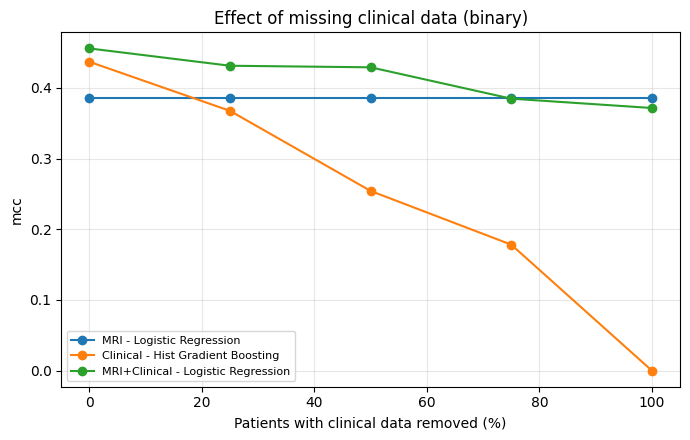

In [35]:
binary["missing"] = run_missing_clinical(y_bin, names_bin)
show_missing("BINARY | PART 4: MRI + CLINICAL WITH MISSING CLINICAL DATA", binary["missing"], "binary")
plot_missing(binary["missing"], "binary", f"binary_missing_plot_{TAG}.png")

# **3-CLASS CLASSIFICATION: grade 2 / grade 3 / grade 4**

## **PART 1: CLINICAL ONLY**

In [51]:
y_3c = patients["who_grade"].map({2: 0, 3: 1, 4: 2}).astype(int).values   # grade 2 = 0, grade 3 = 1, grade 4 = 2
names_3c = ["grade 2", "grade 3", "grade 4"]
three = {}

three["clinical"] = run_clinical_only(y_3c, names_3c)
show("3-CLASS | PART 1: CLINICAL ONLY (age, sex)", three["clinical"])

### **3-CLASS | PART 1: CLINICAL ONLY (age, sex)**

,mcc,balanced_acc,macro_f1,auc,accuracy,recall grade 2,recall grade 3,recall grade 4
model,,,,,,,,
Decision Tree,0.219 ± 0.060,0.442 ± 0.055,0.399 ± 0.036,0.666 ± 0.037,0.615 ± 0.052,0.389 ± 0.188,0.250 ± 0.152,0.688 ± 0.072
Hist Gradient Boosting,0.187 ± 0.047,0.432 ± 0.045,0.384 ± 0.029,0.686 ± 0.033,0.560 ± 0.045,0.429 ± 0.146,0.255 ± 0.151,0.612 ± 0.060
Logistic Regression,0.311 ± 0.061,0.532 ± 0.068,0.476 ± 0.039,0.766 ± 0.034,0.677 ± 0.024,0.609 ± 0.133,0.255 ± 0.156,0.732 ± 0.032
Random Forest,0.198 ± 0.039,0.410 ± 0.040,0.392 ± 0.030,0.666 ± 0.028,0.647 ± 0.029,0.399 ± 0.104,0.087 ± 0.084,0.743 ± 0.038
SVM,0.005 ± 0.019,0.335 ± 0.005,0.299 ± 0.011,0.766 ± 0.039,0.799 ± 0.005,0.006 ± 0.022,0.000 ± 0.000,0.998 ± 0.007


## **PART 2: MRI ONLY**

In [52]:
three["mri"] = run_mri_only(y_3c, names_3c)
show("3-CLASS | PART 2: MRI ONLY", three["mri"])

### **3-CLASS | PART 2: MRI ONLY**

,mcc,balanced_acc,macro_f1,auc,accuracy,recall grade 2,recall grade 3,recall grade 4
model,,,,,,,,
Decision Tree,0.134 ± 0.084,0.432 ± 0.086,0.363 ± 0.046,0.594 ± 0.068,0.496 ± 0.070,0.477 ± 0.212,0.296 ± 0.186,0.521 ± 0.105
Hist Gradient Boosting,0.274 ± 0.098,0.462 ± 0.063,0.454 ± 0.056,0.691 ± 0.059,0.776 ± 0.025,0.430 ± 0.188,0.053 ± 0.083,0.904 ± 0.030
Logistic Regression,0.265 ± 0.053,0.496 ± 0.054,0.449 ± 0.036,0.721 ± 0.052,0.656 ± 0.032,0.562 ± 0.172,0.209 ± 0.140,0.718 ± 0.046
Random Forest,0.139 ± 0.111,0.364 ± 0.027,0.351 ± 0.043,0.708 ± 0.061,0.804 ± 0.012,0.102 ± 0.082,0.000 ± 0.000,0.991 ± 0.012
SVM,0.242 ± 0.129,0.401 ± 0.046,0.397 ± 0.056,0.738 ± 0.051,0.811 ± 0.019,0.220 ± 0.140,0.000 ± 0.000,0.982 ± 0.013


## **PART 3: MRI + CLINICAL (multimodal)**

In [53]:
three["multimodal"] = run_multimodal(y_3c, names_3c)
show("3-CLASS | PART 3: MRI + CLINICAL (multimodal)", three["multimodal"])

### **3-CLASS | PART 3: MRI + CLINICAL (multimodal)**

,mcc,balanced_acc,macro_f1,auc,accuracy,recall grade 2,recall grade 3,recall grade 4
model,,,,,,,,
Decision Tree,0.322 ± 0.056,0.551 ± 0.047,0.476 ± 0.036,0.686 ± 0.058,0.663 ± 0.054,0.636 ± 0.174,0.315 ± 0.166,0.704 ± 0.073
Hist Gradient Boosting,0.340 ± 0.090,0.504 ± 0.072,0.492 ± 0.054,0.769 ± 0.048,0.785 ± 0.027,0.532 ± 0.209,0.082 ± 0.079,0.897 ± 0.039
Logistic Regression,0.336 ± 0.074,0.538 ± 0.066,0.496 ± 0.052,0.786 ± 0.048,0.712 ± 0.040,0.555 ± 0.145,0.277 ± 0.163,0.781 ± 0.054
Random Forest,0.317 ± 0.116,0.438 ± 0.057,0.435 ± 0.060,0.801 ± 0.046,0.822 ± 0.016,0.334 ± 0.179,0.000 ± 0.000,0.980 ± 0.012
SVM,0.378 ± 0.131,0.473 ± 0.058,0.469 ± 0.061,0.800 ± 0.036,0.829 ± 0.025,0.447 ± 0.172,0.000 ± 0.000,0.973 ± 0.017


## **PART 4: MRI + CLINICAL WITH MISSING CLINICAL DATA**

### **3-CLASS | PART 4: MRI + CLINICAL WITH MISSING CLINICAL DATA**

**macro_f1** (mean ± sd over seeds and folds)

scenario,0% missing,25% missing,50% missing,75% missing,100% missing,only age missing,only sex missing
model,,,,,,,
Clinical - Decision Tree,0.393 ± 0.061,0.365 ± 0.071,0.323 ± 0.101,0.261 ± 0.113,0.154 ± 0.121,0.187 ± 0.121,0.378 ± 0.063
Clinical - Hist Gradient Boosting,0.394 ± 0.047,0.360 ± 0.057,0.317 ± 0.057,0.259 ± 0.093,0.155 ± 0.120,0.182 ± 0.117,0.384 ± 0.053
Clinical - Logistic Regression,0.484 ± 0.044,0.435 ± 0.060,0.393 ± 0.093,0.306 ± 0.092,0.187 ± 0.121,0.210 ± 0.108,0.415 ± 0.085
Clinical - Random Forest,0.388 ± 0.046,0.347 ± 0.042,0.318 ± 0.049,0.245 ± 0.078,0.122 ± 0.109,0.202 ± 0.108,0.415 ± 0.050
Clinical - SVM,0.296 ± 0.001,0.296 ± 0.001,0.296 ± 0.001,0.296 ± 0.001,0.296 ± 0.001,0.296 ± 0.001,0.296 ± 0.001
MRI - Decision Tree,0.364 ± 0.056,0.364 ± 0.056,0.364 ± 0.056,0.364 ± 0.056,0.364 ± 0.056,0.364 ± 0.056,0.364 ± 0.056
MRI - Hist Gradient Boosting,0.440 ± 0.068,0.440 ± 0.068,0.440 ± 0.068,0.440 ± 0.068,0.440 ± 0.068,0.440 ± 0.068,0.440 ± 0.068
MRI - Logistic Regression,0.452 ± 0.036,0.452 ± 0.036,0.452 ± 0.036,0.452 ± 0.036,0.452 ± 0.036,0.452 ± 0.036,0.452 ± 0.036
MRI - Random Forest,0.360 ± 0.046,0.360 ± 0.046,0.360 ± 0.046,0.360 ± 0.046,0.360 ± 0.046,0.360 ± 0.046,0.360 ± 0.046


**balanced_acc** (mean ± sd over seeds and folds)

scenario,0% missing,25% missing,50% missing,75% missing,100% missing,only age missing,only sex missing
model,,,,,,,
Clinical - Decision Tree,0.450 ± 0.065,0.421 ± 0.061,0.395 ± 0.063,0.377 ± 0.039,0.333 ± 0.000,0.333 ± 0.000,0.441 ± 0.072
Clinical - Hist Gradient Boosting,0.443 ± 0.064,0.408 ± 0.056,0.392 ± 0.034,0.364 ± 0.041,0.333 ± 0.000,0.330 ± 0.022,0.447 ± 0.059
Clinical - Logistic Regression,0.543 ± 0.065,0.482 ± 0.066,0.441 ± 0.068,0.381 ± 0.038,0.333 ± 0.000,0.327 ± 0.030,0.503 ± 0.072
Clinical - Random Forest,0.418 ± 0.072,0.383 ± 0.069,0.397 ± 0.045,0.372 ± 0.040,0.333 ± 0.000,0.336 ± 0.036,0.453 ± 0.050
Clinical - SVM,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000,0.333 ± 0.000
MRI - Decision Tree,0.427 ± 0.093,0.427 ± 0.093,0.427 ± 0.093,0.427 ± 0.093,0.427 ± 0.093,0.427 ± 0.093,0.427 ± 0.093
MRI - Hist Gradient Boosting,0.448 ± 0.073,0.448 ± 0.073,0.448 ± 0.073,0.448 ± 0.073,0.448 ± 0.073,0.448 ± 0.073,0.448 ± 0.073
MRI - Logistic Regression,0.498 ± 0.050,0.498 ± 0.050,0.498 ± 0.050,0.498 ± 0.050,0.498 ± 0.050,0.498 ± 0.050,0.498 ± 0.050
MRI - Random Forest,0.370 ± 0.029,0.370 ± 0.029,0.370 ± 0.029,0.370 ± 0.029,0.370 ± 0.029,0.370 ± 0.029,0.370 ± 0.029


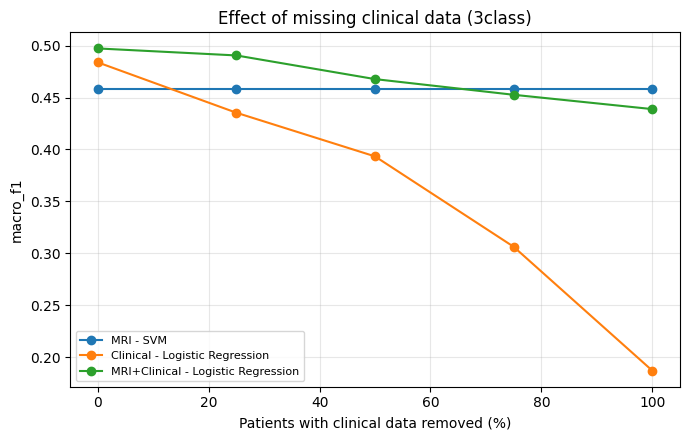

In [36]:
three["missing"] = run_missing_clinical(y_3c, names_3c)
show_missing("3-CLASS | PART 4: MRI + CLINICAL WITH MISSING CLINICAL DATA", three["missing"], "3class")
plot_missing(three["missing"], "3class", f"3class_missing_plot_{TAG}.png")

# **5. SAVE RESULTS AND WRITE THE FINAL REPORT**

In [55]:
if "missing" not in binary:
    print("Running missing clinical data experiment for binary task...")
    binary["missing"] = run_missing_clinical(y_bin, names_bin)

if "missing" not in three:
    print("Running missing clinical data experiment for 3-class task...")
    three["missing"] = run_missing_clinical(y_3c, names_3c)

# Save everything: two Excel files (one per task), two plots (already saved) and the final report
save_task("binary", binary)
save_task("3class", three)
report = make_report([("binary", "Binary classification: grade 2/3 vs grade 4", y_bin, names_bin, binary),
                      ("3class", "Three-class classification: grade 2 / grade 3 / grade 4", y_3c, names_3c, three)])
display(Markdown(report))
print(f"Saved: results_binary_{TAG}.xlsx, results_3class_{TAG}.xlsx, binary_missing_plot_{TAG}.png, 3class_missing_plot_{TAG}.png, final_report_{TAG}.md")

Running missing clinical data experiment for binary task...
Running missing clinical data experiment for 3-class task...


# Final report: MRI, clinical and multimodal glioma grade classification (UCSF-PDGM)

## What was done

- Data: 495 patients, one tumour slice per patient, 4 MRI sequences (T1, T1c, T2, FLAIR) and age + sex.
- MRI features: frozen ResNet50 (ImageNet) numbers, reduced with PCA.
- MRI models: Logistic Regression, Decision Tree, Random Forest, SVM, Hist Gradient Boosting. Clinical models: Logistic Regression, Decision Tree, Random Forest, SVM, Hist Gradient Boosting. Multimodal models: Logistic Regression, Decision Tree, Random Forest, SVM, Hist Gradient Boosting. Training with missing values: True.
- Evaluation: 5-fold patient-level cross-validation repeated with seeds [42, 43, 44].
- Order of work: binary task first (grade 4 vs grade 2/3), then three classes (grade 2 / 3 / 4). Each task has four parts: clinical only, MRI only, MRI + clinical, MRI + clinical with missing clinical data.

## Binary classification: grade 2/3 vs grade 4

Patients: 495 (grade 2/3: 99, grade 4: 396). Main metric: MCC. Every number is mean ± standard deviation over 3 seeds x 5 patient-level folds.

### Part 1. Clinical only (age, sex)
Models used: Decision Tree, Hist Gradient Boosting, Logistic Regression, Random Forest, SVM.
Best by MCC: **Hist Gradient Boosting** (0.439).

| model | mcc | balanced_acc | macro_f1 | auc | accuracy | recall grade 2/3 | recall grade 4 |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0.435 ± 0.062 | 0.744 ± 0.035 | 0.708 ± 0.032 | 0.757 ± 0.053 | 0.785 ± 0.027 | 0.677 ± 0.076 | 0.812 ± 0.036 |
| Hist Gradient Boosting | 0.439 ± 0.061 | 0.749 ± 0.033 | 0.709 ± 0.033 | 0.755 ± 0.054 | 0.783 ± 0.029 | 0.693 ± 0.058 | 0.806 ± 0.034 |
| Logistic Regression | 0.425 ± 0.059 | 0.749 ± 0.037 | 0.693 ± 0.028 | 0.795 ± 0.052 | 0.761 ± 0.023 | 0.730 ± 0.081 | 0.769 ± 0.032 |
| Random Forest | 0.389 ± 0.083 | 0.715 ± 0.043 | 0.687 ± 0.045 | 0.714 ± 0.054 | 0.774 ± 0.041 | 0.616 ± 0.074 | 0.813 ± 0.049 |
| SVM | 0.260 ± 0.089 | 0.603 ± 0.047 | 0.611 ± 0.054 | 0.780 ± 0.053 | 0.796 ± 0.023 | 0.282 ± 0.119 | 0.924 ± 0.040 |

### Part 2. MRI only
Models used: Decision Tree, Hist Gradient Boosting, Logistic Regression, Random Forest, SVM.
Best by MCC: **Logistic Regression** (0.392).

| model | mcc | balanced_acc | macro_f1 | auc | accuracy | recall grade 2/3 | recall grade 4 |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0.193 ± 0.094 | 0.612 ± 0.057 | 0.575 ± 0.045 | 0.633 ± 0.058 | 0.671 ± 0.059 | 0.512 ± 0.168 | 0.711 ± 0.100 |
| Hist Gradient Boosting | 0.241 ± 0.092 | 0.627 ± 0.056 | 0.617 ± 0.043 | 0.722 ± 0.034 | 0.746 ± 0.023 | 0.428 ± 0.134 | 0.826 ± 0.038 |
| Logistic Regression | 0.392 ± 0.056 | 0.727 ± 0.030 | 0.680 ± 0.032 | 0.796 ± 0.032 | 0.754 ± 0.036 | 0.680 ± 0.066 | 0.773 ± 0.051 |
| Random Forest | 0.275 ± 0.118 | 0.582 ± 0.041 | 0.592 ± 0.056 | 0.762 ± 0.029 | 0.815 ± 0.021 | 0.195 ± 0.085 | 0.970 ± 0.023 |
| SVM | 0.324 ± 0.132 | 0.609 ± 0.052 | 0.626 ± 0.066 | 0.778 ± 0.045 | 0.821 ± 0.029 | 0.255 ± 0.106 | 0.962 ± 0.031 |

### Part 3. MRI + clinical (multimodal)
Models used: Decision Tree, Hist Gradient Boosting, Logistic Regression, Random Forest, SVM.
Best by MCC: **Logistic Regression** (0.447).

| model | mcc | balanced_acc | macro_f1 | auc | accuracy | recall grade 2/3 | recall grade 4 |
|---|---|---|---|---|---|---|---|
| Decision Tree | 0.425 ± 0.089 | 0.745 ± 0.051 | 0.697 ± 0.046 | 0.751 ± 0.077 | 0.768 ± 0.041 | 0.707 ± 0.096 | 0.784 ± 0.049 |
| Hist Gradient Boosting | 0.386 ± 0.101 | 0.698 ± 0.055 | 0.692 ± 0.050 | 0.823 ± 0.031 | 0.798 ± 0.032 | 0.532 ± 0.103 | 0.865 ± 0.029 |
| Logistic Regression | 0.447 ± 0.073 | 0.752 ± 0.039 | 0.714 ± 0.038 | 0.855 ± 0.038 | 0.789 ± 0.033 | 0.690 ± 0.068 | 0.814 ± 0.037 |
| Random Forest | 0.394 ± 0.115 | 0.660 ± 0.059 | 0.682 ± 0.062 | 0.836 ± 0.028 | 0.831 ± 0.028 | 0.376 ± 0.116 | 0.944 ± 0.022 |
| SVM | 0.437 ± 0.100 | 0.686 ± 0.047 | 0.709 ± 0.049 | 0.840 ± 0.037 | 0.838 ± 0.027 | 0.434 ± 0.089 | 0.939 ± 0.025 |

### Part 4. MRI + clinical with missing clinical data
Table: MCC for each model and each amount of missing clinical data.

| model | 0% missing | 25% missing | 50% missing | 75% missing | 100% missing | only age missing | only sex missing |
|---|---|---|---|---|---|---|---|
| Clinical - Decision Tree | 0.433 ± 0.071 | 0.359 ± 0.081 | 0.270 ± 0.093 | 0.161 ± 0.078 | 0.000 ± 0.000 | -0.007 ± 0.021 | 0.414 ± 0.095 |
| Clinical - Hist Gradient Boosting | 0.437 ± 0.077 | 0.367 ± 0.082 | 0.254 ± 0.104 | 0.178 ± 0.078 | 0.000 ± 0.000 | -0.015 ± 0.045 | 0.432 ± 0.082 |
| Clinical - Logistic Regression | 0.410 ± 0.070 | 0.357 ± 0.096 | 0.261 ± 0.100 | 0.118 ± 0.092 | 0.000 ± 0.000 | -0.007 ± 0.038 | 0.409 ± 0.081 |
| Clinical - Random Forest | 0.299 ± 0.075 | 0.253 ± 0.062 | 0.175 ± 0.077 | 0.142 ± 0.082 | 0.000 ± 0.000 | -0.003 ± 0.047 | 0.353 ± 0.105 |
| Clinical - SVM | 0.056 ± 0.131 | 0.049 ± 0.129 | 0.047 ± 0.135 | 0.025 ± 0.052 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.040 ± 0.121 |
| MRI - Decision Tree | 0.182 ± 0.080 | 0.182 ± 0.080 | 0.182 ± 0.080 | 0.182 ± 0.080 | 0.182 ± 0.080 | 0.182 ± 0.080 | 0.182 ± 0.080 |
| MRI - Hist Gradient Boosting | 0.239 ± 0.097 | 0.239 ± 0.097 | 0.239 ± 0.097 | 0.239 ± 0.097 | 0.239 ± 0.097 | 0.239 ± 0.097 | 0.239 ± 0.097 |
| MRI - Logistic Regression | 0.386 ± 0.069 | 0.386 ± 0.069 | 0.386 ± 0.069 | 0.386 ± 0.069 | 0.386 ± 0.069 | 0.386 ± 0.069 | 0.386 ± 0.069 |
| MRI - Random Forest | 0.273 ± 0.116 | 0.273 ± 0.116 | 0.273 ± 0.116 | 0.273 ± 0.116 | 0.273 ± 0.116 | 0.273 ± 0.116 | 0.273 ± 0.116 |
| MRI - SVM | 0.306 ± 0.119 | 0.306 ± 0.119 | 0.306 ± 0.119 | 0.306 ± 0.119 | 0.306 ± 0.119 | 0.306 ± 0.119 | 0.306 ± 0.119 |
| MRI+Clinical - Decision Tree | 0.376 ± 0.075 | 0.339 ± 0.087 | 0.291 ± 0.098 | 0.237 ± 0.091 | 0.189 ± 0.099 | 0.189 ± 0.099 | 0.376 ± 0.075 |
| MRI+Clinical - Hist Gradient Boosting | 0.399 ± 0.062 | 0.385 ± 0.063 | 0.310 ± 0.073 | 0.264 ± 0.103 | 0.225 ± 0.094 | 0.227 ± 0.092 | 0.398 ± 0.062 |
| MRI+Clinical - Logistic Regression | 0.456 ± 0.064 | 0.431 ± 0.064 | 0.429 ± 0.079 | 0.385 ± 0.056 | 0.371 ± 0.080 | 0.376 ± 0.105 | 0.452 ± 0.065 |
| MRI+Clinical - Random Forest | 0.390 ± 0.110 | 0.370 ± 0.142 | 0.304 ± 0.091 | 0.255 ± 0.122 | 0.206 ± 0.138 | 0.211 ± 0.137 | 0.391 ± 0.106 |
| MRI+Clinical - SVM | 0.418 ± 0.129 | 0.396 ± 0.119 | 0.353 ± 0.130 | 0.312 ± 0.113 | 0.298 ± 0.136 | 0.286 ± 0.144 | 0.413 ± 0.134 |

Effect of missing clinical data on each multimodal model:

- MRI+Clinical - Decision Tree: MCC 0.376 with full clinical data and 0.189 with all clinical data missing (change -0.187, larger than the fold-to-fold spread). Only age missing: 0.189; only sex missing: 0.376.
- MRI+Clinical - Hist Gradient Boosting: MCC 0.399 with full clinical data and 0.225 with all clinical data missing (change -0.174, larger than the fold-to-fold spread). Only age missing: 0.227; only sex missing: 0.398.
- MRI+Clinical - Logistic Regression: MCC 0.456 with full clinical data and 0.371 with all clinical data missing (change -0.084, larger than the fold-to-fold spread). Only age missing: 0.376; only sex missing: 0.452.
- MRI+Clinical - Random Forest: MCC 0.390 with full clinical data and 0.206 with all clinical data missing (change -0.184, larger than the fold-to-fold spread). Only age missing: 0.211; only sex missing: 0.391.
- MRI+Clinical - SVM: MCC 0.418 with full clinical data and 0.298 with all clinical data missing (change -0.119, inside the fold-to-fold spread). Only age missing: 0.286; only sex missing: 0.413.

Reference points with all clinical data missing: Clinical - Decision Tree 0.000; Clinical - Hist Gradient Boosting 0.000; Clinical - Logistic Regression 0.000; Clinical - Random Forest 0.000; Clinical - SVM 0.000; best MRI-only model (Logistic Regression) 0.392.

## Three-class classification: grade 2 / grade 3 / grade 4

Patients: 495 (grade 2: 56, grade 3: 43, grade 4: 396). Main metric: macro-F1. Every number is mean ± standard deviation over 3 seeds x 5 patient-level folds.

### Part 1. Clinical only (age, sex)
Models used: Decision Tree, Hist Gradient Boosting, Logistic Regression, Random Forest, SVM.
Best by macro-F1: **Logistic Regression** (0.476).

| model | mcc | balanced_acc | macro_f1 | auc | accuracy | recall grade 2 | recall grade 3 | recall grade 4 |
|---|---|---|---|---|---|---|---|---|
| Decision Tree | 0.219 ± 0.060 | 0.442 ± 0.055 | 0.399 ± 0.036 | 0.666 ± 0.037 | 0.615 ± 0.052 | 0.389 ± 0.188 | 0.250 ± 0.152 | 0.688 ± 0.072 |
| Hist Gradient Boosting | 0.187 ± 0.047 | 0.432 ± 0.045 | 0.384 ± 0.029 | 0.686 ± 0.033 | 0.560 ± 0.045 | 0.429 ± 0.146 | 0.255 ± 0.151 | 0.612 ± 0.060 |
| Logistic Regression | 0.311 ± 0.061 | 0.532 ± 0.068 | 0.476 ± 0.039 | 0.766 ± 0.034 | 0.677 ± 0.024 | 0.609 ± 0.133 | 0.255 ± 0.156 | 0.732 ± 0.032 |
| Random Forest | 0.198 ± 0.039 | 0.410 ± 0.040 | 0.392 ± 0.030 | 0.666 ± 0.028 | 0.647 ± 0.029 | 0.399 ± 0.104 | 0.087 ± 0.084 | 0.743 ± 0.038 |
| SVM | 0.005 ± 0.019 | 0.335 ± 0.005 | 0.299 ± 0.011 | 0.766 ± 0.039 | 0.799 ± 0.005 | 0.006 ± 0.022 | 0.000 ± 0.000 | 0.998 ± 0.007 |

### Part 2. MRI only
Models used: Decision Tree, Hist Gradient Boosting, Logistic Regression, Random Forest, SVM.
Best by macro-F1: **Hist Gradient Boosting** (0.454).

| model | mcc | balanced_acc | macro_f1 | auc | accuracy | recall grade 2 | recall grade 3 | recall grade 4 |
|---|---|---|---|---|---|---|---|---|
| Decision Tree | 0.134 ± 0.084 | 0.432 ± 0.086 | 0.363 ± 0.046 | 0.594 ± 0.068 | 0.496 ± 0.070 | 0.477 ± 0.212 | 0.296 ± 0.186 | 0.521 ± 0.105 |
| Hist Gradient Boosting | 0.274 ± 0.098 | 0.462 ± 0.063 | 0.454 ± 0.056 | 0.691 ± 0.059 | 0.776 ± 0.025 | 0.430 ± 0.188 | 0.053 ± 0.083 | 0.904 ± 0.030 |
| Logistic Regression | 0.265 ± 0.053 | 0.496 ± 0.054 | 0.449 ± 0.036 | 0.721 ± 0.052 | 0.656 ± 0.032 | 0.562 ± 0.172 | 0.209 ± 0.140 | 0.718 ± 0.046 |
| Random Forest | 0.139 ± 0.111 | 0.364 ± 0.027 | 0.351 ± 0.043 | 0.708 ± 0.061 | 0.804 ± 0.012 | 0.102 ± 0.082 | 0.000 ± 0.000 | 0.991 ± 0.012 |
| SVM | 0.242 ± 0.129 | 0.401 ± 0.046 | 0.397 ± 0.056 | 0.738 ± 0.051 | 0.811 ± 0.019 | 0.220 ± 0.140 | 0.000 ± 0.000 | 0.982 ± 0.013 |

### Part 3. MRI + clinical (multimodal)
Models used: Decision Tree, Hist Gradient Boosting, Logistic Regression, Random Forest, SVM.
Best by macro-F1: **Logistic Regression** (0.496).

| model | mcc | balanced_acc | macro_f1 | auc | accuracy | recall grade 2 | recall grade 3 | recall grade 4 |
|---|---|---|---|---|---|---|---|---|
| Decision Tree | 0.322 ± 0.056 | 0.551 ± 0.047 | 0.476 ± 0.036 | 0.686 ± 0.058 | 0.663 ± 0.054 | 0.636 ± 0.174 | 0.315 ± 0.166 | 0.704 ± 0.073 |
| Hist Gradient Boosting | 0.340 ± 0.090 | 0.504 ± 0.072 | 0.492 ± 0.054 | 0.769 ± 0.048 | 0.785 ± 0.027 | 0.532 ± 0.209 | 0.082 ± 0.079 | 0.897 ± 0.039 |
| Logistic Regression | 0.336 ± 0.074 | 0.538 ± 0.066 | 0.496 ± 0.052 | 0.786 ± 0.048 | 0.712 ± 0.040 | 0.555 ± 0.145 | 0.277 ± 0.163 | 0.781 ± 0.054 |
| Random Forest | 0.317 ± 0.116 | 0.438 ± 0.057 | 0.435 ± 0.060 | 0.801 ± 0.046 | 0.822 ± 0.016 | 0.334 ± 0.179 | 0.000 ± 0.000 | 0.980 ± 0.012 |
| SVM | 0.378 ± 0.131 | 0.473 ± 0.058 | 0.469 ± 0.061 | 0.800 ± 0.036 | 0.829 ± 0.025 | 0.447 ± 0.172 | 0.000 ± 0.000 | 0.973 ± 0.017 |

### Part 4. MRI + clinical with missing clinical data
Table: macro-F1 for each model and each amount of missing clinical data.

| model | 0% missing | 25% missing | 50% missing | 75% missing | 100% missing | only age missing | only sex missing |
|---|---|---|---|---|---|---|---|
| Clinical - Decision Tree | 0.393 ± 0.061 | 0.365 ± 0.071 | 0.323 ± 0.101 | 0.261 ± 0.113 | 0.154 ± 0.121 | 0.187 ± 0.121 | 0.378 ± 0.063 |
| Clinical - Hist Gradient Boosting | 0.394 ± 0.047 | 0.360 ± 0.057 | 0.317 ± 0.057 | 0.259 ± 0.093 | 0.155 ± 0.120 | 0.182 ± 0.117 | 0.384 ± 0.053 |
| Clinical - Logistic Regression | 0.484 ± 0.044 | 0.435 ± 0.060 | 0.393 ± 0.093 | 0.306 ± 0.092 | 0.187 ± 0.121 | 0.210 ± 0.108 | 0.415 ± 0.085 |
| Clinical - Random Forest | 0.388 ± 0.046 | 0.347 ± 0.042 | 0.318 ± 0.049 | 0.245 ± 0.078 | 0.122 ± 0.109 | 0.202 ± 0.108 | 0.415 ± 0.050 |
| Clinical - SVM | 0.296 ± 0.001 | 0.296 ± 0.001 | 0.296 ± 0.001 | 0.296 ± 0.001 | 0.296 ± 0.001 | 0.296 ± 0.001 | 0.296 ± 0.001 |
| MRI - Decision Tree | 0.364 ± 0.056 | 0.364 ± 0.056 | 0.364 ± 0.056 | 0.364 ± 0.056 | 0.364 ± 0.056 | 0.364 ± 0.056 | 0.364 ± 0.056 |
| MRI - Hist Gradient Boosting | 0.440 ± 0.068 | 0.440 ± 0.068 | 0.440 ± 0.068 | 0.440 ± 0.068 | 0.440 ± 0.068 | 0.440 ± 0.068 | 0.440 ± 0.068 |
| MRI - Logistic Regression | 0.452 ± 0.036 | 0.452 ± 0.036 | 0.452 ± 0.036 | 0.452 ± 0.036 | 0.452 ± 0.036 | 0.452 ± 0.036 | 0.452 ± 0.036 |
| MRI - Random Forest | 0.360 ± 0.046 | 0.360 ± 0.046 | 0.360 ± 0.046 | 0.360 ± 0.046 | 0.360 ± 0.046 | 0.360 ± 0.046 | 0.360 ± 0.046 |
| MRI - SVM | 0.458 ± 0.045 | 0.458 ± 0.045 | 0.458 ± 0.045 | 0.458 ± 0.045 | 0.458 ± 0.045 | 0.458 ± 0.045 | 0.458 ± 0.045 |
| MRI+Clinical - Decision Tree | 0.414 ± 0.056 | 0.389 ± 0.065 | 0.379 ± 0.083 | 0.340 ± 0.086 | 0.308 ± 0.116 | 0.308 ± 0.116 | 0.414 ± 0.056 |
| MRI+Clinical - Hist Gradient Boosting | 0.473 ± 0.055 | 0.455 ± 0.045 | 0.449 ± 0.046 | 0.436 ± 0.056 | 0.428 ± 0.063 | 0.428 ± 0.063 | 0.472 ± 0.052 |
| MRI+Clinical - Logistic Regression | 0.497 ± 0.048 | 0.491 ± 0.062 | 0.468 ± 0.070 | 0.453 ± 0.062 | 0.439 ± 0.067 | 0.441 ± 0.061 | 0.490 ± 0.047 |
| MRI+Clinical - Random Forest | 0.415 ± 0.062 | 0.401 ± 0.051 | 0.384 ± 0.047 | 0.370 ± 0.043 | 0.341 ± 0.049 | 0.343 ± 0.055 | 0.409 ± 0.066 |
| MRI+Clinical - SVM | 0.497 ± 0.069 | 0.473 ± 0.055 | 0.464 ± 0.064 | 0.448 ± 0.051 | 0.433 ± 0.046 | 0.425 ± 0.056 | 0.493 ± 0.067 |

Effect of missing clinical data on each multimodal model:

- MRI+Clinical - Decision Tree: macro-F1 0.414 with full clinical data and 0.308 with all clinical data missing (change -0.106, larger than the fold-to-fold spread). Only age missing: 0.308; only sex missing: 0.414.
- MRI+Clinical - Hist Gradient Boosting: macro-F1 0.473 with full clinical data and 0.428 with all clinical data missing (change -0.045, inside the fold-to-fold spread). Only age missing: 0.428; only sex missing: 0.472.
- MRI+Clinical - Logistic Regression: macro-F1 0.497 with full clinical data and 0.439 with all clinical data missing (change -0.058, larger than the fold-to-fold spread). Only age missing: 0.441; only sex missing: 0.490.
- MRI+Clinical - Random Forest: macro-F1 0.415 with full clinical data and 0.341 with all clinical data missing (change -0.074, larger than the fold-to-fold spread). Only age missing: 0.343; only sex missing: 0.409.
- MRI+Clinical - SVM: macro-F1 0.497 with full clinical data and 0.433 with all clinical data missing (change -0.064, inside the fold-to-fold spread). Only age missing: 0.425; only sex missing: 0.493.

Reference points with all clinical data missing: Clinical - Decision Tree 0.154; Clinical - Hist Gradient Boosting 0.155; Clinical - Logistic Regression 0.187; Clinical - Random Forest 0.122; Clinical - SVM 0.296; best MRI-only model (Hist Gradient Boosting) 0.454.

## Previous work and earlier runs

- Kheirbakhsh et al. (2026, medRxiv preprint, not peer reviewed): UCSF-PDGM, 495 patients, MRI + age + sex, grade 2&3 vs 4, slice-level evaluation with fine-tuned DenseNet121. Clinical-only: accuracy 0.80, MCC 0.44. Best single MRI sequence (T1c): accuracy 0.83, MCC 0.48. Best fusion: accuracy 0.86, MCC 0.54. Check the numbers in the PDF before citing. A missing-clinical-data test was not seen in that paper.
- Earlier run in this project (notebook 04, binary task, frozen ResNet50 features, mean over 3 seeds x 5 folds): MRI-only MCC 0.392; clinical-only MCC 0.451; concatenation fusion MCC 0.447; with all clinical data removed fusion MCC 0.361, MRI-only 0.392, clinical-only 0.000.
- Earlier scratch-CNN baseline (tumor.ipynb, 3 classes, MRI only, one split of 75 test patients): accuracy 0.8133, balanced accuracy 0.4019, macro-F1 0.3978; almost every patient was predicted as grade 4.

These earlier numbers use other models and settings, so compare only the direction of the effects.

## How to read these results

- No significance tests are included here. Differences smaller than the standard deviation should not be treated as real.
- One tumour slice per patient, MRI described by frozen ResNet50 features (no fine-tuning), only age and sex as clinical data.
- Missing clinical data is simulated by hiding values; it is not real hospital missingness.
- Grade 2 and grade 3 have few patients, so three-class results (especially their per-class recall) are unstable.
- Dataset: UCSF-PDGM (Calabrese et al., 2022), Hugging Face copy MedOtter/UCSF-PDGM (CC BY 4.0). Cite the original dataset.


Saved: results_binary_train_with_missing.xlsx, results_3class_train_with_missing.xlsx, binary_missing_plot_train_with_missing.png, 3class_missing_plot_train_with_missing.png, final_report_train_with_missing.md
